In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# to load the dataset
from datasets import load_dataset

In [28]:
emotion_dataset = load_dataset("dair-ai/emotion")
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

val_text = emotion_dataset['validation']['text']
val_label = emotion_dataset['validation']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

print("Training samples:", len(train_text))
print("Validation samples:", len(val_text))
print("Testing samples:", len(test_text))

Training samples: 16000
Validation samples: 2000
Testing samples: 2000


In [29]:
print("Train:")
print(train_text[0])
print(train_label[0])

print("\nValidation:")
print(val_text[0])
print(val_label[0])

print("\nTest:")
print(test_text[0])
print(test_label[0])

Train:
i didnt feel humiliated
0

Validation:
im feeling quite sad and sorry for myself but ill snap out of it soon
0

Test:
im feeling rather rotten so im not very ambitious right now
0


In [30]:
from collections import Counter

print("Train:", Counter(train_label))
print("Validation:", Counter(val_label))
print("Test:", Counter(test_label))

Train: Counter({1: 5362, 0: 4666, 3: 2159, 4: 1937, 2: 1304, 5: 572})
Validation: Counter({1: 704, 0: 550, 3: 275, 4: 212, 2: 178, 5: 81})
Test: Counter({1: 695, 0: 581, 3: 275, 4: 224, 2: 159, 5: 66})


In [31]:
label_name = emotion_dataset['train'].features['label'].names


In [32]:
print(emotion_dataset['train'].features['label'])

for i, name in enumerate(label_name):
    print(i, name)

ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])
0 sadness
1 joy
2 love
3 anger
4 fear
5 surprise


In [33]:
df_train = pd.DataFrame(
    {
        "text": train_text,
        "label" : [label_name[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        "text": test_text,
        "label" : [label_name[i] for i in test_label]
    }
)
df_val = pd.DataFrame(
    {
        "text": val_text,
        "label" : [label_name[i] for i in val_label]
    }
)

In [34]:
df_train.head()



,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [35]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [36]:
df_val.head()

,text,label
0,im feeling quite sad and sorry for myself but ...,sadness
1,i feel like i am still looking at a blank canv...,sadness
2,i feel like a faithful servant,love
3,i am just feeling cranky and blue,anger
4,i can have for a treat or if i am feeling festive,joy


<Axes: xlabel='label', ylabel='count'>

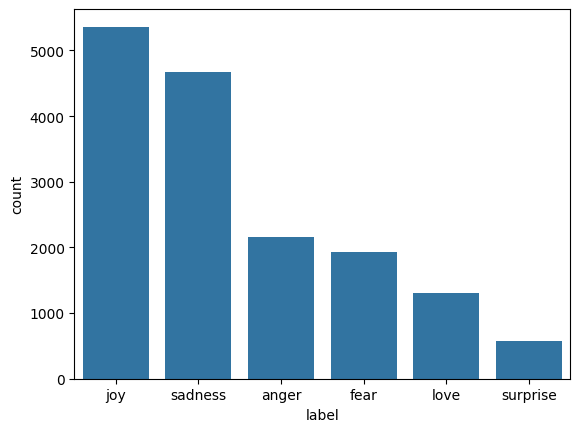

In [37]:
#EDA

sns.countplot(x = "label", data = df_train, order = df_train.label.value_counts().index)

In [38]:
# data preprocessing for NLP
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = "<unk>")
tokenizer.fit_on_texts(df_train.text)

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
val_sequences = tokenizer.texts_to_sequences(df_val['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequences = pad_sequences(train_sequences, maxlen = 50, padding = "post", truncating = "post")
padded_test_sequences = pad_sequences(test_sequences, maxlen = 50, padding = "post", truncating = "post")
padded_val_sequences = pad_sequences(val_sequences, maxlen = 50, padding = "post", truncating = "post")

train_labels = np.array(train_label)
val_labels = np.array(val_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print("Train:", padded_train_sequences.shape, train_labels.shape)
print("Validation:", padded_val_sequences.shape, val_labels.shape)
print("Test:", padded_test_sequences.shape, test_labels.shape)

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequences.shape[1]}")

Train: (16000, 50) (16000,)
Validation: (2000, 50) (2000,)
Test: (2000, 50) (2000,)
Vocabulary Size: 15213
Max Sentence Length: 50


In [39]:
# calculating class weights
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = "balanced",
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

# early stopping
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = "val_loss",
    patience = 3,
    restore_best_weights = True
)

In [40]:
#phase 1 plain foundational model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    SimpleRNN(units= 128, return_sequences = True),
    Dropout(0.5),
    SimpleRNN(units= 64),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

rnn_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
rnn_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.1517 - loss: 2.0551 - val_accuracy: 0.2045 - val_loss: 1.7590
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1371 - loss: 1.8967 - val_accuracy: 0.1515 - val_loss: 1.7714
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1264 - loss: 1.8288 - val_accuracy: 0.0750 - val_loss: 1.8034
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1381 - loss: 1.8083 - val_accuracy: 0.1035 - val_loss: 1.8095
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2045 - loss: 1.7590
RNN Loss: 1.758971095085144
RNN Accuracy: 0.2045000046491623


In [41]:
#LSTM MODEL
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    LSTM(units= 128, return_sequences = True),
    Dropout(0.5),
    LSTM(units= 64),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

lstm_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
lstm_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1476 - loss: 1.7944 - val_accuracy: 0.1380 - val_loss: 1.7845
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1419 - loss: 1.7944 - val_accuracy: 0.0830 - val_loss: 1.7772
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1421 - loss: 1.7936 - val_accuracy: 0.1385 - val_loss: 1.7726
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1380 - loss: 1.7845
LSTM Loss: 1.7844504117965698
LSTM Accuracy: 0.1379999965429306


In [42]:
#GRU MODEL
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    GRU(units= 128, return_sequences = True),
    Dropout(0.5),
    GRU(units= 64),
    Dropout(0.5),
    Dense(num_classes, activation = "softmax") # output layer
])

gru_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy', metrics=["accuracy"])
gru_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data = (padded_test_sequences, test_labels),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)
gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1383 - loss: 1.7967 - val_accuracy: 0.1350 - val_loss: 1.7910
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1650 - loss: 1.7955 - val_accuracy: 0.1365 - val_loss: 1.7959
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1555 - loss: 1.7942 - val_accuracy: 0.0855 - val_loss: 1.7891
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1350 - loss: 1.7910
GRU Loss: 1.7909973859786987
GRU Accuracy: 0.13500000536441803


In [43]:
result_df = pd.DataFrame({
    "model": ["RNN","LSTM","GRYU"],
    "test_loss": [rnn_loss, lstm_loss, gru_loss],
    "test_accuracy": [rnn_accuracy, lstm_accuracy, gru_accuracy]
})

In [44]:
# bidirectional GRU
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

BiGRU.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_val_sequences, val_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequences, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")



Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.5926 - loss: 1.0135 - val_accuracy: 0.9045 - val_loss: 0.3302
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9239 - loss: 0.2119 - val_accuracy: 0.9240 - val_loss: 0.2363
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9444 - loss: 0.1502 - val_accuracy: 0.9325 - val_loss: 0.1804
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9608 - loss: 0.1070 - val_accuracy: 0.9210 - val_loss: 0.2383
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9686 - loss: 0.0862 - val_accuracy: 0.9220 - val_loss: 0.2910
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9753 - loss: 0.0688 - val_accuracy: 0.9200 - val_loss: 0.2950
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9235 - loss: 0.1931
BiGRU Loss: 0.19313667714595795
BiGRU Accuracy: 0.9235000014305115


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


<Axes: >

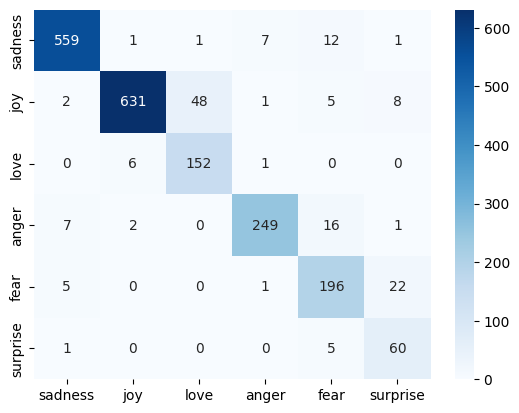

In [45]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequences),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_name, yticklabels=label_name)

In [46]:
sample_texts = [
    # JOY
    "I can't believe how happy I am right now, this is amazing!",
    "Today has been the best day of my entire life.",
    "I finally got the job I've been dreaming about for years.",
    "Spending time with my family makes everything feel better.",
    "I couldn't stop smiling after hearing the good news.",
    "All my hard work finally paid off and I feel incredible.",
    "I am so excited about starting this new chapter.",
    "The entire room was filled with laughter and happiness.",
    "I feel grateful for everything happening in my life.",
    "Nothing makes me happier than seeing my friends succeed.",

    # SADNESS
    "I feel so alone and hopeless today.",
    "Sometimes I feel like nobody really understands me.",
    "I miss the days when everything seemed so simple.",
    "I tried my best, but somehow everything still went wrong.",
    "I feel empty even when everyone around me is happy.",
    "Losing someone you love leaves a pain that never completely disappears.",
    "I wish things could go back to how they used to be.",
    "I spent the entire night thinking about everything I lost.",
    "It hurts when people slowly become strangers.",
    "I don't know why, but today everything feels overwhelming.",

    # ANGER
    "I am furious that they cancelled the trip at the last minute.",
    "I cannot believe they lied to me after everything I did for them.",
    "It makes me angry when people refuse to take responsibility.",
    "I am tired of being blamed for everyone else's mistakes.",
    "How dare they treat me like I don't matter?",
    "I have explained this problem a hundred times and nobody listens.",
    "Their careless attitude is absolutely unacceptable.",
    "I am beyond frustrated with these constant delays.",
    "They promised to help but abandoned me when I needed them.",
    "I have had enough of their disrespectful behaviour.",

    # FEAR
    "I feel terrified when walking down dark alleyways alone.",
    "I keep imagining everything that could possibly go wrong.",
    "My heart started racing when I heard someone behind me.",
    "I am scared that I might lose everything I have worked for.",
    "What if something terrible happens while I am away?",
    "I cannot sleep because I keep worrying about tomorrow.",
    "The thought of speaking in front of hundreds of people makes me nervous.",
    "I felt helpless when the lights suddenly went out.",
    "I am afraid that nobody will believe what I saw.",
    "Every unexpected sound makes me feel like something is wrong.",

    # SURPRISE
    "I was shocked and completely surprised by the unexpected gift!",
    "I never imagined they would actually remember my birthday.",
    "Wait, you mean we won the competition?",
    "I cannot believe how quickly everything changed.",
    "Nobody expected him to show up after all these years.",
    "I opened the door and found everyone waiting for me.",
    "That announcement completely caught me off guard.",
    "I had absolutely no idea this was going to happen.",
    "The results were completely different from what I expected.",
    "I was speechless when I discovered the truth.",

    # LOVE
    "I feel incredibly lucky to have someone who understands me.",
    "Every moment with you feels special.",
    "I would do anything to see you smile.",
    "Being around my family makes me feel safe and loved.",
    "I still get butterflies whenever I see her.",
    "Your kindness means more to me than you will ever know.",
    "I cannot imagine my life without these wonderful people.",
    "Even after all these years, I fall in love with you again.",
    "I cherish every little memory we have created together.",
    "You make me feel like I truly belong somewhere.",

    # SARCASM
    "Oh fantastic, another deadline that I definitely needed today.",
    "It's genuinely impressive how everything managed to fall apart exactly as I expected, yet somehow I'm still the one pretending to be surprised.",
    "Wow, what a brilliant idea to ignore every warning I gave you.",
    "I absolutely love waiting three hours for something that should take five minutes.",
    "Great, just what I needed, another problem to deal with.",

    # MIXED EMOTIONS
    "I'm happy that she succeeded, but honestly I wish I had that opportunity too.",
    "I am excited about moving abroad, but leaving my family makes me sad.",
    "I love spending time with them, even though they sometimes drive me crazy.",
    "I feel relieved that everything is over, but disappointed with how it ended.",
    "I am proud of what I achieved, yet somehow I still feel empty.",

    # NEGATION
    "I am not angry, just disappointed that nobody kept their promise.",
    "I don't feel sad anymore, but I still miss those memories.",
    "I was not expecting such a wonderful surprise.",
    "I am not afraid of failing, I am afraid of never trying.",
    "I don't hate them, I just don't trust them anymore.",

    # CONTEXTUAL EMOTIONS
    "After everything that happened, I just sat there wondering why I even tried.",
    "She smiled when she heard the news, but her eyes told a different story.",
    "He said everything was fine, although his voice was shaking.",
    "I laughed at the situation because crying wouldn't change anything.",
    "I knew this would happen, but somehow it still hurts."
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_predictions[i]]}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: Today has been the best day of my entire life.
Predicted Emotion: sadness
Text: I finally got the job I've been dreaming about for years.
Predicted Emotion: fear
Text: Spending time with my family makes everything feel better.
Predicted Emotion: joy
Text: I couldn't stop smiling after hearing the good news.
Predicted Emotion: fear
Text: All my hard work finally paid off and I feel incredible.
Predicted Emotion: joy
Text: I am so excited about starting this new chapter.
Predicted Emotion: fear
Text: The entire room was filled with laughter and happiness.
Predicted Emotion: sadness
Text: I feel grateful for everything happening in my life.
Predicted Emotion: joy
Text: Nothing makes me happier than seeing my friends succeed.
Predicted Emotion: fear
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: Sometimes I feel like nobody rea

In [47]:
import numpy as np

print("TRAIN")
print("Text:", len(train_text))
print("Sequences:", len(padded_train_sequences))
print("train_label:", len(train_label))
print("train_labels:", len(train_labels))

print("\nVALIDATION")
print("Text:", len(val_text))
print("Sequences:", len(padded_val_sequences))
print("val_label:", len(val_label))
print("val_labels:", len(val_labels))

print("\nTEST")
print("Text:", len(test_text))
print("Sequences:", len(padded_test_sequences))
print("test_label:", len(test_label))
print("test_labels:", len(test_labels))

print("\nLABEL COMPARISON")
print("Train labels identical:",
      np.array_equal(train_label, train_labels))

print("Validation labels identical:",
      np.array_equal(val_label, val_labels))

print("Test labels identical:",
      np.array_equal(test_label, test_labels))

TRAIN
Text: 16000
Sequences: 16000
train_label: 16000
train_labels: 16000

VALIDATION
Text: 2000
Sequences: 2000
val_label: 2000
val_labels: 2000

TEST
Text: 2000
Sequences: 2000
test_label: 2000
test_labels: 2000

LABEL COMPARISON
Train labels identical: True
Validation labels identical: True
Test labels identical: True


In [48]:
print("Expected validation size:",
      len(emotion_dataset['validation']))

print("Actual validation text size:", len(val_text))
print("Actual validation label size:", len(val_labels))
print("Actual validation sequence size:",
      len(padded_val_sequences))

Expected validation size: 2000
Actual validation text size: 2000
Actual validation label size: 2000
Actual validation sequence size: 2000


In [49]:
from collections import Counter

predictions = BiGRU.predict(padded_test_sequences)

predicted_classes = np.argmax(predictions, axis=1)

print("Actual distribution:",
      Counter(test_labels))

print("Predicted distribution:",
      Counter(predicted_classes))

print("First 10 predictions:")
for i in range(10):
    print({
        "text": test_text[i],
        "actual": label_name[test_labels[i]],
        "predicted": label_name[predicted_classes[i]]
    })

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Actual distribution: Counter({np.int64(1): 695, np.int64(0): 581, np.int64(3): 275, np.int64(4): 224, np.int64(2): 159, np.int64(5): 66})
Predicted distribution: Counter({np.int64(1): 640, np.int64(0): 574, np.int64(3): 259, np.int64(4): 234, np.int64(2): 201, np.int64(5): 92})
First 10 predictions:
{'text': 'im feeling rather rotten so im not very ambitious right now', 'actual': 'sadness', 'predicted': 'sadness'}
{'text': 'im updating my blog because i feel shitty', 'actual': 'sadness', 'predicted': 'sadness'}
{'text': 'i never make her separate from me because i don t ever want her to feel like i m ashamed with her', 'actual': 'sadness', 'predicted': 'sadness'}
{'text': 'i left with my bouquet of red and yellow tulips under my arm feeling slightly more optimistic than when i arrived', 'actual': 'joy', 'predicted': 'joy'}
{'text': 'i was feeling a little vain when i did this one', 'actual': 'sadness', 'predicted': 'sadness'}
{'text': 'i cant walk

In [50]:
# Recreate sequences independently
check_train = tokenizer.texts_to_sequences(train_text)
check_val = tokenizer.texts_to_sequences(val_text)
check_test = tokenizer.texts_to_sequences(test_text)

# Compare with your existing sequences
print("Train sequences match:",
      np.array_equal(
          padded_train_sequences,
          pad_sequences(check_train, maxlen=50, padding='post', truncating='post')
      ))

print("Validation sequences match:",
      np.array_equal(
          padded_val_sequences,
          pad_sequences(check_val, maxlen=50, padding='post', truncating='post')
      ))

print("Test sequences match:",
      np.array_equal(
          padded_test_sequences,
          pad_sequences(check_test, maxlen=50, padding='post', truncating='post')
      ))

Train sequences match: True
Validation sequences match: True
Test sequences match: True


In [51]:
print("Vocabulary size:", len(tokenizer.word_index))

for name, texts in [
    ("Train", train_text),
    ("Validation", val_text),
    ("Test", test_text)
]:
    sequences = tokenizer.texts_to_sequences(texts)

    total_tokens = sum(len(text.split()) for text in texts)
    unknown_tokens = sum(
        token == 1
        for sequence in sequences
        for token in sequence
    )

    print(f"\n{name}")
    print("Total original words:", total_tokens)
    print("Unknown tokens:", unknown_tokens)
    print(
        "Unknown token percentage:",
        round(unknown_tokens / max(total_tokens, 1) * 100, 2),
        "%"
    )

Vocabulary size: 15213

Train
Total original words: 306661
Unknown tokens: 5214
Unknown token percentage: 1.7 %

Validation
Total original words: 37732
Unknown tokens: 1358
Unknown token percentage: 3.6 %

Test
Total original words: 38308
Unknown tokens: 1425
Unknown token percentage: 3.72 %


In [52]:

import numpy as np
import pandas as pd

predictions = BiGRU.predict(padded_test_sequences)
predicted_labels = np.argmax(predictions, axis=1)

results = pd.DataFrame({
    "text": test_text,
    "actual": [label_name[i] for i in test_labels],
    "predicted": [label_name[i] for i in predicted_labels],
    "confidence": np.max(predictions, axis=1)
})

# Most important confusion: Joy predicted as Love
joy_love_errors = results[
    (results["actual"] == "joy") &
    (results["predicted"] == "love")
]

# Fear predicted as Surprise
fear_surprise_errors = results[
    (results["actual"] == "fear") &
    (results["predicted"] == "surprise")
]

print("JOY → LOVE ERRORS")
display(joy_love_errors.head(25))

print("FEAR → SURPRISE ERRORS")
display(fear_surprise_errors.head(25))


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
JOY → LOVE ERRORS


,text,actual,predicted,confidence
262,i realized what i am passionate about helping ...,joy,love,0.943410
304,i feel like i should be supporting them someho...,joy,love,0.593658
335,i believe that feeling accepted in a non judge...,joy,love,0.696654
353,i could feel his breath on me and smell the sw...,joy,love,0.924142
376,i suppose if one was feeling generous one coul...,joy,love,0.942720
408,i feel quite passionate about and that is how ...,joy,love,0.755929
436,i hope shes feeling generous today and treat m...,joy,love,0.529135
489,i believe that people should choose the causes...,joy,love,0.770778
496,i never feel like im not supporting,joy,love,0.823914
531,i feel like i am not accepted here i and bucki...,joy,love,0.905877


FEAR → SURPRISE ERRORS


,text,actual,predicted,confidence
93,i was feeling weird the other day and it went ...,fear,surprise,0.628164
108,i looked at mabel this morning i named my left...,fear,surprise,0.912474
188,i feel kinda weird when andrea tries to talk t...,fear,surprise,0.595884
295,i feel strange talking about less serious thin...,fear,surprise,0.516677
305,i have a lot going on in my life and feel over...,fear,surprise,0.764409
319,i indicated then i was feeling quite overwhelm...,fear,surprise,0.848490
421,i began to feel very strange,fear,surprise,0.540153
457,i cant do strappy shoes at work i just feel we...,fear,surprise,0.865426
460,i have moments where i just feel so overwhelme...,fear,surprise,0.620289
694,i wept while jackson slept feeling overwhelmed...,fear,surprise,0.721808


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [53]:
pd.set_option('display.max_colwidth', None)

fear_surprise_errors = results[
    (results["actual"] == "fear") &
    (results["predicted"] == "surprise")
]

display(
    fear_surprise_errors[
        ["text", "actual", "predicted", "confidence"]
    ].sort_values("confidence", ascending=False)
)

,text,actual,predicted,confidence
1469,i already feel he is using us it feels weird because i havent even done anything there yet but i feel it coming like ministry coming at me,fear,surprise,0.943470
1162,i would always have this song stuck in my head after a bombing or incident and then i would feel a bit weird about it because if you dont really pay attention to the lyrics it sounds like such a happy song not the type youre supposed to hum on difficult days,fear,surprise,0.928120
108,i looked at mabel this morning i named my left breast mabel my right one is hazel and i feel this weird mixture of anger and loss valerie wrote less than a month after her diagnosis,fear,surprise,0.912474
1747,i did feel slightly weird in that costume,fear,surprise,0.883955
832,i think and it feels a little weird,fear,surprise,0.869839
457,i cant do strappy shoes at work i just feel weird so i took these off thrifted ninewest,fear,surprise,0.865426
1517,i could have expected in every way and i was feeling a bit overwhelmed at that point how quickly life changed in the past weeks,fear,surprise,0.854282
319,i indicated then i was feeling quite overwhelmed with work responsibilities teaching traveling and writing,fear,surprise,0.848490
1322,i started to feel so overwhelmed,fear,surprise,0.796516
1062,i know how that feels weird right,fear,surprise,0.785768


In [54]:
keywords = [
    "weird",
    "strange",
    "overwhelmed",
    "uncertain",
    "unexpected",
    "surprised",
    "scared",
    "afraid",
    "worried"
]

for word in keywords:
    count = fear_surprise_errors["text"].str.contains(
        rf"\b{word}\b",
        case=False,
        regex=True
    ).sum()

    print(f"{word}: {count}")

weird: 12
strange: 3
overwhelmed: 7
uncertain: 1
unexpected: 0
surprised: 0
scared: 0
afraid: 0
worried: 0


In [55]:
error_indices = fear_surprise_errors.index

for idx in error_indices:
    print("\nText:", results.loc[idx, "text"])

    probabilities = predictions[idx]

    for emotion_id in np.argsort(probabilities)[::-1][:3]:
        print(
            f"{label_name[emotion_id]}: "
            f"{probabilities[emotion_id]:.4f}"
        )


Text: i was feeling weird the other day and it went away about minutes after i took my metformin
surprise: 0.6282
fear: 0.3673
anger: 0.0023

Text: i looked at mabel this morning i named my left breast mabel my right one is hazel and i feel this weird mixture of anger and loss valerie wrote less than a month after her diagnosis
surprise: 0.9125
fear: 0.0826
joy: 0.0024

Text: i feel kinda weird when andrea tries to talk to me about chris
surprise: 0.5959
fear: 0.3957
joy: 0.0054

Text: i feel strange talking about less serious things right now like cooking
surprise: 0.5167
fear: 0.4792
joy: 0.0020

Text: i have a lot going on in my life and feel overwhelmed
surprise: 0.7644
fear: 0.2319
anger: 0.0021

Text: i indicated then i was feeling quite overwhelmed with work responsibilities teaching traveling and writing
surprise: 0.8485
fear: 0.1457
joy: 0.0034

Text: i began to feel very strange
surprise: 0.5402
fear: 0.4572
anger: 0.0010

Text: i cant do strappy shoes at work i just feel we

In [56]:
import pandas as pd
import re

train_analysis = pd.DataFrame({
    "text": train_text,
    "label": [label_name[i] for i in train_labels]
})

keywords = [
    "weird",
    "strange",
    "overwhelmed",
    "uncertain"
]

for word in keywords:

    matches = train_analysis[
        train_analysis["text"].str.contains(
            rf"\b{word}\b",
            case=False,
            regex=True,
            na=False
        )
    ]

    print(f"\nKeyword: {word}")
    print("Total occurrences:", len(matches))

    print(
        matches["label"]
        .value_counts()
        .reindex(label_name, fill_value=0)
    )


Keyword: weird
Total occurrences: 130
label
sadness      8
joy          7
love         1
anger        0
fear        58
surprise    56
Name: count, dtype: int64

Keyword: strange
Total occurrences: 141
label
sadness      8
joy          6
love         1
anger        3
fear        78
surprise    45
Name: count, dtype: int64

Keyword: overwhelmed
Total occurrences: 138
label
sadness     13
joy          6
love         0
anger        5
fear        56
surprise    58
Name: count, dtype: int64

Keyword: uncertain
Total occurrences: 64
label
sadness      3
joy          1
love         0
anger        0
fear        60
surprise     0
Name: count, dtype: int64


In [57]:
joy_love_errors = results[
    (results["actual"] == "joy") &
    (results["predicted"] == "love")
]

display(
    joy_love_errors[
        ["text", "actual", "predicted", "confidence"]
    ].sort_values(
        "confidence",
        ascending=False
    )
)

,text,actual,predicted,confidence
1959,i check you when you re sleeping feel your nose and toes to be sure you aren t too hot or cold,joy,love,0.986569
845,i did feel rather like a celebrity and widget stood and let herself be admired while she drank orange squash from my cup,joy,love,0.977023
1729,i felt like id developed feelings for this guy thus explaining why id even follow this guy like a faithful puppy dog and he never knew,joy,love,0.969379
576,i feel accepted and loved by a community of derby girls that i helped to create,joy,love,0.955805
262,i realized what i am passionate about helping women feel accepted and appreciated,joy,love,0.943410
376,i suppose if one was feeling generous one could say i was stressed by the elevator ride,joy,love,0.942720
1924,i never dreamed i would be so busy so soon in the new year but i am loving it and feeling so very gracious and fortunate,joy,love,0.941698
1764,i don t know how else to describe it except to say that i had the same feeling about three weeks before my beloved grandmother passed away,joy,love,0.930515
1708,i just tell people i feel like one sweet southern mess right now,joy,love,0.926899
1558,i don t know about you but it makes me feel generous,joy,love,0.925002


In [59]:

keywords = [
    "accepted",
    "loved",
    "love",
    "passionate",
    "blessed",
    "generous",
    "faithful",
    "beloved",
    "grateful",
    "happy",
    "excited",
    "supporting"
]

for word in keywords:

    matches = train_analysis[
        train_analysis["text"].str.contains(
            rf"\b{word}\b",
            case=False,
            regex=True,
            na=False
        )
    ]

    print(f"\nKeyword: {word}")
    print("Total:", len(matches))

    print(
        matches["label"]
        .value_counts()
        .reindex(label_name, fill_value=0)
    )



Keyword: accepted
Total: 111
label
sadness      2
joy         58
love        46
anger        1
fear         4
surprise     0
Name: count, dtype: int64

Keyword: loved
Total: 120
label
sadness     18
joy         36
love        52
anger        4
fear         7
surprise     3
Name: count, dtype: int64

Keyword: love
Total: 447
label
sadness      99
joy         173
love         85
anger        41
fear         37
surprise     12
Name: count, dtype: int64

Keyword: passionate
Total: 116
label
sadness      2
joy         51
love        61
anger        0
fear         1
surprise     1
Name: count, dtype: int64

Keyword: blessed
Total: 121
label
sadness      6
joy         61
love        47
anger        5
fear         1
surprise     1
Name: count, dtype: int64

Keyword: generous
Total: 93
label
sadness      2
joy         51
love        40
anger        0
fear         0
surprise     0
Name: count, dtype: int64

Keyword: faithful
Total: 55
label
sadness      0
joy         28
love        27
anger    

In [60]:
comparison_texts = [
    "I feel happy because I finally got my dream job.",
    "I feel happy because I am spending time with someone I love.",
    "I love the excitement of achieving my goals.",
    "I feel deeply connected and attached to someone.",
    "I am grateful because my hard work finally paid off.",
    "I am grateful to have someone who genuinely cares about me.",
    "I feel passionate about building my career.",
    "I feel passionate about the person I love.",
    "I feel blessed to have achieved my goals.",
    "I feel blessed to have my family beside me.",
]

comparison_sequences = tokenizer.texts_to_sequences(comparison_texts)

comparison_padded = pad_sequences(
    comparison_sequences,
    maxlen=50,
    padding="post",
    truncating="post"
)

comparison_predictions = BiGRU.predict(comparison_padded)

for text, probabilities in zip(
    comparison_texts,
    comparison_predictions
):
    top_indices = np.argsort(probabilities)[::-1][:3]

    print("\n", text)

    for idx in top_indices:
        print(f"{label_name[idx]}: {probabilities[idx]:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step

 I feel happy because I finally got my dream job.
joy: 0.9957
love: 0.0023
sadness: 0.0016

 I feel happy because I am spending time with someone I love.
joy: 0.9931
sadness: 0.0033
love: 0.0029

 I love the excitement of achieving my goals.
anger: 0.3900
fear: 0.3608
sadness: 0.2302

 I feel deeply connected and attached to someone.
joy: 0.9861
love: 0.0078
fear: 0.0035

 I am grateful because my hard work finally paid off.
fear: 0.4409
surprise: 0.2394
sadness: 0.2323

 I am grateful to have someone who genuinely cares about me.
fear: 0.4524
anger: 0.3112
sadness: 0.2130

 I feel passionate about building my career.
joy: 0.8978
love: 0.1009
fear: 0.0008

 I feel passionate about the person I love.
love: 0.9138
joy: 0.0848
anger: 0.0009

 I feel blessed to have achieved my goals.
love: 0.8441
joy: 0.1518
anger: 0.0030

 I feel blessed to have my family beside me.
love: 0.7047
joy: 0.2932
sadness: 0.0011


In [61]:
import joblib
joblib.dump(BiGRU, 'Bigru_model.keras')
joblib.dump(tokenizer, 'tokenizer.pkl')


['tokenizer.pkl']